# Data Preparation and Analysis Using Python
## Online Retail Dataset

**Programme:** M.Tech CSE (Artificial Intelligence) – 2026  
**Subject:** Data Preparation and Analysis (DPA)  
**Dataset:** Online Retail  
**Tools:** Python, NumPy, Pandas, Matplotlib, Seaborn and Plotly

### Problem statement
Analyze online retail transactions to understand sales patterns, product demand, customer activity and country-wise performance. The work includes data cleaning, exploratory data analysis (EDA), visualization and feature engineering.

### Objectives
1. Load and understand the Online Retail CSV dataset.
2. Perform NumPy array operations and descriptive statistics.
3. Inspect and clean missing values, duplicate records and invalid transactions.
4. Explore numerical and categorical variables.
5. Create static and interactive visualizations.
6. Engineer useful features from transaction and date information.
7. Summarize findings, conclusions and limitations.

## Step 1: Dataset Collection

The Online Retail dataset contains transactional records from an online retail business. Each row represents an item on an invoice.

**Dataset source:** [Kaggle – Online Retail](https://www.kaggle.com/datasets/vijayuv/onlineretail)  
**Original dataset documentation:** [UCI Machine Learning Repository – Online Retail](https://archive.ics.uci.edu/dataset/352/online+retail)

**Important columns**
- `InvoiceNo`: Invoice number; invoices beginning with `C` indicate cancellations.
- `StockCode`: Product code.
- `Description`: Product description.
- `Quantity`: Number of items purchased; negative values can represent returns.
- `InvoiceDate`: Date and time of the transaction.
- `UnitPrice`: Price per item.
- `CustomerID`: Customer identifier.
- `Country`: Customer's country.

**Dataset path:** Keep `OnlineRetail.csv` in the same folder as this notebook. In Google Colab, upload the CSV to the session or change the path below.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

possible_paths = [
    "OnlineRetail.csv",
    "/content/OnlineRetail.csv",
    "/mnt/data/OnlineRetail.csv"
]
dataset_path = next((p for p in possible_paths if os.path.exists(p)), None)

if dataset_path is None:
    raise FileNotFoundError(
        "OnlineRetail.csv not found. Place it beside this notebook "
        "or upload it to /content in Google Colab."
    )

df = pd.read_csv(dataset_path, encoding="ISO-8859-1")
print("Dataset loaded successfully!")
print("File:", dataset_path)
print("Original shape:", df.shape)
display(df.head())

Dataset loaded successfully!
File: OnlineRetail.csv
Original shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,"17,850.00",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,"17,850.00",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,"17,850.00",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,"17,850.00",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,"17,850.00",United Kingdom


## Step 2: Python and NumPy Operations

The numerical columns `Quantity` and `UnitPrice` are converted into NumPy arrays. Array creation, indexing, slicing, arithmetic and descriptive statistics are demonstrated below.

In [2]:
# Convert selected columns to NumPy arrays
quantity_array = df["Quantity"].to_numpy()
price_array = df["UnitPrice"].to_numpy()

print("First 10 quantities:", quantity_array[:10])
print("First 10 unit prices:", price_array[:10])

# Array creation, indexing and slicing
sample_array = np.array([10, 20, 30, 40, 50])
print("\nSample array:", sample_array)
print("First element:", sample_array[0])
print("Elements from index 1 to 3:", sample_array[1:4])
print("Array multiplied by 2:", sample_array * 2)

# Arithmetic operation: line revenue (including negative quantities/returns)
line_revenue_array = quantity_array * price_array
print("\nFirst 10 line revenue values:", line_revenue_array[:10])

# NumPy descriptive statistics for unit price and quantity
for column_name, values in [("Quantity", quantity_array), ("UnitPrice", price_array)]:
    print(f"\n{column_name} statistics")
    print("Mean:", np.nanmean(values))
    print("Median:", np.nanmedian(values))
    print("Standard deviation:", np.nanstd(values))
    print("Minimum:", np.nanmin(values))
    print("Maximum:", np.nanmax(values))
    print("25th percentile:", np.nanpercentile(values, 25))
    print("75th percentile:", np.nanpercentile(values, 75))

First 10 quantities: [ 6  6  8  6  6  2  6  6  6 32]
First 10 unit prices: [2.55 3.39 2.75 3.39 3.39 7.65 4.25 1.85 1.85 1.69]

Sample array: [10 20 30 40 50]
First element: 10
Elements from index 1 to 3: [20 30 40]
Array multiplied by 2: [ 20  40  60  80 100]

First 10 line revenue values: [15.3  20.34 22.   20.34 20.34 15.3  25.5  11.1  11.1  54.08]

Quantity statistics
Mean: 9.55224954743324
Median: 3.0
Standard deviation: 218.08095663447764
Minimum: -80995
Maximum: 80995
25th percentile: 1.0
75th percentile: 10.0

UnitPrice statistics
Mean: 4.611113626088514
Median: 2.08
Standard deviation: 96.75976378429183
Minimum: -11062.06
Maximum: 38970.0
25th percentile: 1.25
75th percentile: 4.13


## Step 3: Pandas Operations

Load the dataset into a DataFrame, inspect the first and last records, identify its dimensions, column names, data types and summary statistics. Missing values and duplicate rows are also examined.

In [3]:
print("First five records")
display(df.head())

print("Last five records")
display(df.tail())

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nSummary statistics:")
display(df.describe(include="all").T)

print("\nMissing values by column:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate rows:", df.duplicated().sum())

First five records


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,"17,850.00",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,"17,850.00",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,"17,850.00",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,"17,850.00",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,"17,850.00",United Kingdom


Last five records


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,12/9/2011 12:50,0.85,"12,680.00",France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,12/9/2011 12:50,2.10,"12,680.00",France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,12/9/2011 12:50,4.15,"12,680.00",France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,12/9/2011 12:50,4.15,"12,680.00",France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,12/9/2011 12:50,4.95,"12,680.00",France


Number of rows: 541909
Number of columns: 8

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Data types:
InvoiceNo       object
StockCode       object
Description     object
Quantity         int64
InvoiceDate     object
UnitPrice      float64
CustomerID     float64
Country         object
dtype: object

Summary statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
InvoiceNo,541909,25900,573585,1114,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,"541,909.00",NaN,NaN,NaN,9.55,218.08,"-80,995.00",1.00,3.00,10.00,"80,995.00"
InvoiceDate,541909,23260,10/31/2011 14:41,1114,NaN,NaN,NaN,NaN,NaN,NaN,NaN
UnitPrice,"541,909.00",NaN,NaN,NaN,4.61,96.76,"-11,062.06",1.25,2.08,4.13,"38,970.00"
CustomerID,"406,829.00",NaN,NaN,NaN,"15,287.69","1,713.60","12,346.00","13,953.00","15,152.00","16,791.00","18,287.00"
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Missing values by column:


,Missing Values
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0



Duplicate rows: 5268


## Step 4: Data Cleaning and Preprocessing

The original DataFrame is retained as `df`. A separate copy, `df_clean`, is prepared for analysis.

Cleaning decisions:
1. Remove exact duplicate rows.
2. Convert `InvoiceDate` into datetime format.
3. Fill missing product descriptions with `Unknown`.
4. Keep missing `CustomerID` values as missing because an unknown customer must not be assigned an invented identity. Customer-level analysis will exclude these records.
5. Remove zero-quantity and non-positive-price records from the analysis dataset.
6. Retain negative quantities because they can represent returned goods or credit transactions.
7. Detect outliers using the IQR method. Outliers are flagged, not automatically deleted, because unusually large orders may be genuine.

In [4]:
# Work on a copy; preserve the original data in df
df_clean = df.copy()

before_rows = len(df_clean)
duplicate_count = df_clean.duplicated().sum()
df_clean = df_clean.drop_duplicates().copy()

# Correct data types and missing descriptions
df_clean["InvoiceDate"] = pd.to_datetime(
    df_clean["InvoiceDate"], errors="coerce"
)
df_clean["Description"] = df_clean["Description"].fillna("Unknown")

# Remove rows with unusable dates, zero quantity, or non-positive unit price
invalid_date_count = df_clean["InvoiceDate"].isna().sum()
zero_quantity_count = (df_clean["Quantity"] == 0).sum()
nonpositive_price_count = (df_clean["UnitPrice"] <= 0).sum()

df_clean = df_clean.dropna(subset=["InvoiceDate"])
df_clean = df_clean[df_clean["Quantity"] != 0]
df_clean = df_clean[df_clean["UnitPrice"] > 0].copy()

print("Rows before cleaning:", before_rows)
print("Duplicate rows removed:", duplicate_count)
print("Rows with invalid dates removed:", invalid_date_count)
print("Zero-quantity rows removed:", zero_quantity_count)
print("Rows with non-positive unit price removed:", nonpositive_price_count)
print("Rows after cleaning:", len(df_clean))
print("Remaining missing values:")
display(df_clean.isnull().sum().to_frame("Missing Values"))
print("Remaining duplicate rows:", df_clean.duplicated().sum())

Rows before cleaning: 541909
Duplicate rows removed: 5268
Rows with invalid dates removed: 0
Zero-quantity rows removed: 0
Rows with non-positive unit price removed: 2512
Rows after cleaning: 534129
Remaining missing values:


,Missing Values
InvoiceNo,0
StockCode,0
Description,0
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,132565
Country,0


Remaining duplicate rows: 0


In [5]:
# Identify outliers using IQR; do not remove them automatically
outlier_summary = {}
for col in ["Quantity", "UnitPrice"]:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((df_clean[col] < lower) | (df_clean[col] > upper)).sum()
    outlier_summary[col] = {
        "Q1": q1, "Q3": q3, "IQR": iqr,
        "Lower Bound": lower, "Upper Bound": upper,
        "Outlier Count": int(count)
    }

print("IQR outlier analysis:")
display(pd.DataFrame(outlier_summary).T)

print("Cleaning comparison:")
display(pd.DataFrame({
    "Before Cleaning": [len(df), df.isnull().sum().sum(), df.duplicated().sum()],
    "After Cleaning": [len(df_clean), df_clean.isnull().sum().sum(), df_clean.duplicated().sum()]
}, index=["Rows", "Missing cells", "Duplicate rows"]))

IQR outlier analysis:


,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count
Quantity,1.00,10.00,9.00,-12.50,23.50,"57,326.00"
UnitPrice,1.25,4.13,2.88,-3.07,8.45,"39,448.00"


Cleaning comparison:


,Before Cleaning,After Cleaning
Rows,541909,534129
Missing cells,136534,132565
Duplicate rows,5268,0


## Step 5: Exploratory Data Analysis (EDA)

EDA is used to understand the distribution of variables, identify patterns and relationships, and compare sales across products, customers, countries and time.

For this analysis, `Revenue` is calculated as `Quantity × UnitPrice`. Negative revenue can occur for returned items and is retained in the transaction-level analysis.

In [6]:
# Add a basic analytical measure
df_clean["Revenue"] = df_clean["Quantity"] * df_clean["UnitPrice"]

print("Numerical descriptive statistics:")
display(df_clean[["Quantity", "UnitPrice", "Revenue"]].describe())

print("\nCategorical variable summaries:")
for col in ["Country", "Description"]:
    print(f"\nTop values for {col}:")
    display(df_clean[col].value_counts().head(10).to_frame("Count"))

print("\nInvoice date range:")
print(df_clean["InvoiceDate"].min(), "to", df_clean["InvoiceDate"].max())

print("\nNumber of unique invoices:", df_clean["InvoiceNo"].nunique())
print("Number of unique products:", df_clean["StockCode"].nunique())
print("Number of identified customers:", df_clean["CustomerID"].nunique())
print("Number of countries:", df_clean["Country"].nunique())

Numerical descriptive statistics:


,Quantity,UnitPrice,Revenue
count,"534,129.00","534,129.00","534,129.00"
mean,9.92,4.70,18.25
std,216.45,95.08,380.95
min,"-80,995.00",0.00,"-168,469.60"
25%,1.00,1.25,3.75
50%,3.00,2.10,9.90
75%,10.00,4.13,17.57
max,"80,995.00","38,970.00","168,469.60"



Categorical variable summaries:

Top values for Country:


,Count
Country,
United Kingdom,487806
Germany,9478
France,8540
EIRE,8180
Spain,2527
Netherlands,2367
Belgium,2069
Switzerland,1993
Portugal,1510



Top values for Description:


,Count
Description,
WHITE HANGING HEART T-LIGHT HOLDER,2353
REGENCY CAKESTAND 3 TIER,2187
JUMBO BAG RED RETROSPOT,2153
PARTY BUNTING,1719
LUNCH BAG RED RETROSPOT,1625
ASSORTED COLOUR BIRD ORNAMENT,1488
SET OF 3 CAKE TINS PANTRY DESIGN,1465
PACK OF 72 RETROSPOT CAKE CASES,1367
LUNCH BAG BLACK SKULL.,1323



Invoice date range:
2010-12-01 08:26:00 to 2011-12-09 12:50:00

Number of unique invoices: 23796


Number of unique products: 3938
Number of identified customers: 4371
Number of countries: 38


In [7]:
# Correlation between numerical variables
numeric_columns = ["Quantity", "UnitPrice", "Revenue"]
correlation_matrix = df_clean[numeric_columns].corr()
print("Correlation matrix:")
display(correlation_matrix)

# Country-wise revenue (top 10 by net revenue)
country_revenue = (
    df_clean.groupby("Country", as_index=False)["Revenue"]
    .sum()
    .sort_values("Revenue", ascending=False)
)
print("Top 10 countries by net revenue:")
display(country_revenue.head(10))

# Monthly revenue
monthly_revenue = (
    df_clean.set_index("InvoiceDate")["Revenue"]
    .resample("MS").sum()
)
display(monthly_revenue.to_frame("Monthly Revenue").head(12))

Correlation matrix:


,Quantity,UnitPrice,Revenue
Quantity,1.00,-0.00,0.90
UnitPrice,-0.00,1.00,-0.18
Revenue,0.90,-0.18,1.00


Top 10 countries by net revenue:


,Country,Revenue
36,United Kingdom,"8,189,252.30"
24,Netherlands,"284,661.54"
10,EIRE,"262,993.38"
14,Germany,"221,509.47"
13,France,"197,317.11"
0,Australia,"137,009.77"
33,Switzerland,"56,363.05"
31,Spain,"54,756.03"
3,Belgium,"40,910.96"
32,Sweden,"36,585.41"


,Monthly Revenue
InvoiceDate,
2010-12-01,"746,723.61"
2011-01-01,"558,448.56"
2011-02-01,"497,026.41"
2011-03-01,"682,013.98"
2011-04-01,"492,367.84"
2011-05-01,"722,094.10"
2011-06-01,"689,977.23"
2011-07-01,"680,156.99"
2011-08-01,"703,510.58"


## Step 6: Data Visualization Using Matplotlib and Seaborn

The following six visualizations address the assignment requirements: histogram, bar chart, line chart, scatter plot, box plot and correlation heatmap. Large transaction data is sampled for scatter plotting to keep the chart readable.

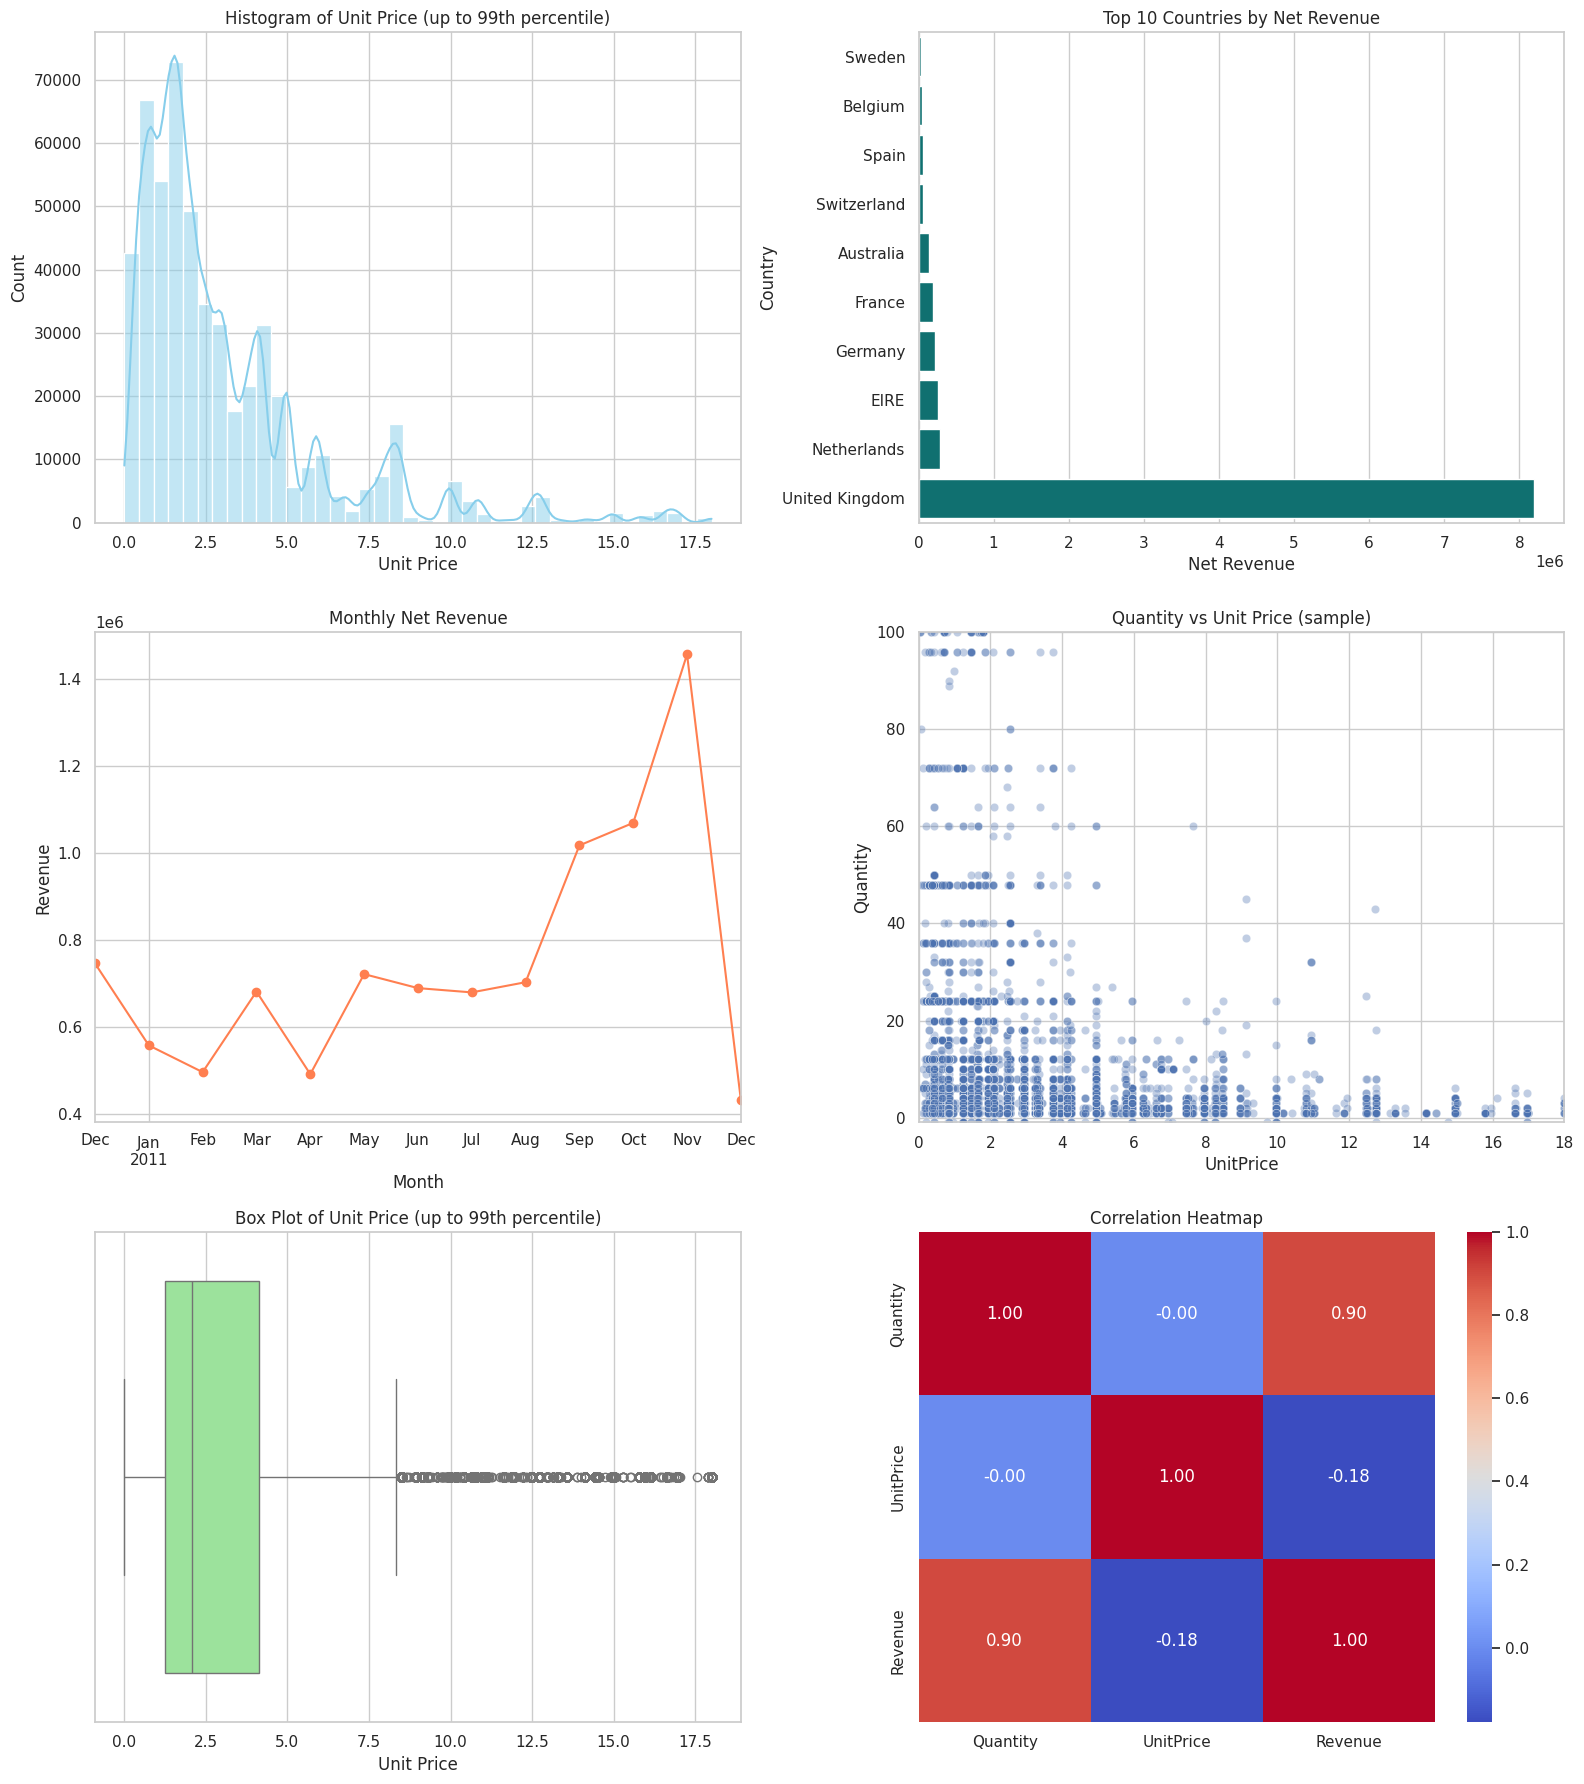

In [8]:
fig, axes = plt.subplots(3, 2, figsize=(16, 18))

# 1. Histogram: unit price distribution (limited to central range for readability)
price_for_plot = df_clean.loc[df_clean["UnitPrice"] <= df_clean["UnitPrice"].quantile(0.99), "UnitPrice"]
sns.histplot(price_for_plot, bins=40, kde=True, ax=axes[0, 0], color="skyblue")
axes[0, 0].set_title("Histogram of Unit Price (up to 99th percentile)")
axes[0, 0].set_xlabel("Unit Price")

# 2. Bar chart: top 10 countries by net revenue
top_countries = country_revenue.head(10).sort_values("Revenue")
sns.barplot(data=top_countries, x="Revenue", y="Country", ax=axes[0, 1], color="teal")
axes[0, 1].set_title("Top 10 Countries by Net Revenue")
axes[0, 1].set_xlabel("Net Revenue")

# 3. Line chart: monthly revenue
monthly_revenue.plot(ax=axes[1, 0], marker="o", color="coral")
axes[1, 0].set_title("Monthly Net Revenue")
axes[1, 0].set_xlabel("Month")
axes[1, 0].set_ylabel("Revenue")

# 4. Scatter plot: quantity vs unit price (sample)
scatter_data = df_clean.sample(n=min(10000, len(df_clean)), random_state=42)
sns.scatterplot(data=scatter_data, x="UnitPrice", y="Quantity", alpha=0.35, ax=axes[1, 1])
axes[1, 1].set_xlim(0, df_clean["UnitPrice"].quantile(0.99))
axes[1, 1].set_ylim(df_clean["Quantity"].quantile(0.01), df_clean["Quantity"].quantile(0.99))
axes[1, 1].set_title("Quantity vs Unit Price (sample)")

# 5. Box plot: unit price outliers
sns.boxplot(x=price_for_plot, ax=axes[2, 0], color="lightgreen")
axes[2, 0].set_title("Box Plot of Unit Price (up to 99th percentile)")
axes[2, 0].set_xlabel("Unit Price")

# 6. Correlation heatmap
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", ax=axes[2, 1])
axes[2, 1].set_title("Correlation Heatmap")

plt.tight_layout()
plt.show()

## Step 7: Interactive Visualization Using Plotly

Three interactive charts are created with titles, axis labels and hover information. A sample is used for the scatter plot to improve browser performance.

In [9]:
import plotly.express as px

# 1. Interactive histogram
fig_hist = px.histogram(
    df_clean, x="UnitPrice", nbins=60,
    title="Interactive Histogram of Unit Price",
    labels={"UnitPrice": "Unit Price"},
    hover_data=["Quantity", "Country"]
)
fig_hist.show()

# 2. Interactive scatter plot
fig_scatter = px.scatter(
    scatter_data, x="UnitPrice", y="Quantity",
    color="Country", hover_data=["Description", "InvoiceDate", "Revenue"],
    title="Interactive Scatter Plot: Quantity vs Unit Price",
    labels={"UnitPrice": "Unit Price", "Quantity": "Quantity"}
)
fig_scatter.show()

# 3. Interactive bar chart
fig_bar = px.bar(
    country_revenue.head(15).sort_values("Revenue", ascending=False),
    x="Country", y="Revenue", color="Revenue",
    title="Interactive Bar Chart: Net Revenue by Country (Top 15)",
    hover_data={"Revenue": ":,.2f"},
    labels={"Revenue": "Net Revenue"}
)
fig_bar.show()

## Step 8: Feature Engineering

Feature engineering creates useful columns from existing data. The following features are created:
1. `Revenue`: Quantity multiplied by unit price.
2. `InvoiceMonth`: Month extracted from the invoice date.
3. `InvoiceYear`: Year extracted from the invoice date.
4. `DayOfWeek`: Day name extracted from the invoice date.
5. `IsReturn`: Identifies transactions with negative quantities.
6. `CountryCode`: Encodes the country category as a numeric code.

A StandardScaler is also applied to selected numeric features. The scaler is fitted only for demonstration of preprocessing; scaled columns are not used to overwrite the original values.

In [10]:
from sklearn.preprocessing import StandardScaler

# Date/time feature extraction
df_clean["InvoiceMonth"] = df_clean["InvoiceDate"].dt.month
df_clean["InvoiceYear"] = df_clean["InvoiceDate"].dt.year
df_clean["DayOfWeek"] = df_clean["InvoiceDate"].dt.day_name()
df_clean["Hour"] = df_clean["InvoiceDate"].dt.hour

# Transaction and categorical features
df_clean["IsReturn"] = (df_clean["Quantity"] < 0).astype(int)
df_clean["CountryCode"] = df_clean["Country"].astype("category").cat.codes

# Revenue was calculated in Step 5; recompute to make the definition explicit
df_clean["Revenue"] = df_clean["Quantity"] * df_clean["UnitPrice"]

engineered_columns = [
    "Revenue", "InvoiceMonth", "InvoiceYear",
    "DayOfWeek", "Hour", "IsReturn", "CountryCode"
]
print("Dataset with engineered features:")
display(df_clean[["InvoiceNo", "Quantity", "UnitPrice", "InvoiceDate", "Country"] + engineered_columns].head())

# Numerical scaling
scale_columns = ["Quantity", "UnitPrice", "Revenue"]
scaler = StandardScaler()
scaled_values = scaler.fit_transform(df_clean[scale_columns])
scaled_names = ["Quantity_Scaled", "UnitPrice_Scaled", "Revenue_Scaled"]
df_clean[scaled_names] = scaled_values

print("Scaled feature sample:")
display(df_clean[scale_columns + scaled_names].head())

Dataset with engineered features:


,InvoiceNo,Quantity,UnitPrice,InvoiceDate,Country,Revenue,InvoiceMonth,InvoiceYear,DayOfWeek,Hour,IsReturn,CountryCode
0,536365,6,2.55,2010-12-01 08:26:00,United Kingdom,15.30,12,2010,Wednesday,8,0,36
1,536365,6,3.39,2010-12-01 08:26:00,United Kingdom,20.34,12,2010,Wednesday,8,0,36
2,536365,8,2.75,2010-12-01 08:26:00,United Kingdom,22.00,12,2010,Wednesday,8,0,36
3,536365,6,3.39,2010-12-01 08:26:00,United Kingdom,20.34,12,2010,Wednesday,8,0,36
4,536365,6,3.39,2010-12-01 08:26:00,United Kingdom,20.34,12,2010,Wednesday,8,0,36


Scaled feature sample:


,Quantity,UnitPrice,Revenue,Quantity_Scaled,UnitPrice_Scaled,Revenue_Scaled
0,6,2.55,15.30,-0.02,-0.02,-0.01
1,6,3.39,20.34,-0.02,-0.01,0.01
2,8,2.75,22.00,-0.01,-0.02,0.01
3,6,3.39,20.34,-0.02,-0.01,0.01
4,6,3.39,20.34,-0.02,-0.01,0.01


## Step 9: Analysis and Conclusion

The following code generates key findings from the cleaned dataset. Interpret the values in the output rather than assuming that all transactions are purchases: negative quantities may represent returns, and missing CustomerID values limit customer-level analysis.

In [11]:
total_transactions = len(df_clean)
identified_customer_rows = df_clean["CustomerID"].notna().sum()
return_rows = int(df_clean["IsReturn"].sum())
net_revenue = df_clean["Revenue"].sum()
top_country = country_revenue.iloc[0]["Country"]
top_country_revenue = country_revenue.iloc[0]["Revenue"]
top_product = (
    df_clean[df_clean["Quantity"] > 0]
    .groupby("Description")["Quantity"].sum()
    .sort_values(ascending=False)
)

print("KEY FINDINGS")
print("1. Cleaned transaction rows:", f"{total_transactions:,}")
print("2. Net revenue across retained records:", f"{net_revenue:,.2f}")
print("3. Country with highest net revenue:", top_country, f"({top_country_revenue:,.2f})")
print("4. Rows with missing CustomerID:", f"{df_clean['CustomerID'].isna().sum():,}")
print("5. Negative-quantity return/credit rows:", f"{return_rows:,}")

if len(top_product) > 0:
    print("6. Product with highest total positive quantity:", top_product.index[0],
          f"({top_product.iloc[0]:,.0f} units)")

print("\nCONCLUSIONS AND RECOMMENDATIONS")
print("- Monthly revenue analysis can help identify seasonal sales patterns.")
print("- Country-wise revenue can help the business compare market performance.")
print("- Product quantity analysis can support inventory planning.")
print("- Return transactions should be monitored because they reduce net revenue.")
print("- Customer-level conclusions should be treated cautiously because some CustomerID values are missing.")

print("\nLIMITATIONS")
print("- The dataset covers a limited historical period and may not represent current retail behaviour.")
print("- Missing CustomerID values prevent complete customer-level analysis.")
print("- Negative quantities may represent returns or credit transactions and need business context.")
print("- Extreme values may be genuine bulk orders; therefore, outliers were flagged rather than automatically removed.")

KEY FINDINGS
1. Cleaned transaction rows: 534,129
2. Net revenue across retained records: 9,748,131.07
3. Country with highest net revenue: United Kingdom (8,189,252.30)
4. Rows with missing CustomerID: 132,565
5. Negative-quantity return/credit rows: 9,251
6. Product with highest total positive quantity: PAPER CRAFT , LITTLE BIRDIE (80,995 units)

CONCLUSIONS AND RECOMMENDATIONS
- Monthly revenue analysis can help identify seasonal sales patterns.
- Country-wise revenue can help the business compare market performance.
- Product quantity analysis can support inventory planning.
- Return transactions should be monitored because they reduce net revenue.
- Customer-level conclusions should be treated cautiously because some CustomerID values are missing.

LIMITATIONS
- The dataset covers a limited historical period and may not represent current retail behaviour.
- Missing CustomerID values prevent complete customer-level analysis.
- Negative quantities may represent returns or credit tra